In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/competitions/comment-category-prediction-challenge/Sample.csv
/kaggle/input/competitions/comment-category-prediction-challenge/train.csv
/kaggle/input/competitions/comment-category-prediction-challenge/test.csv


# 🏆 Milestone 5: End-to-End Refinement — Maximum Kaggle Score

**Lessons from M1-M4 baked in:**
- Macro F1 = THE metric (Kaggle uses this, not accuracy)
- `class_weight='balanced'` is mandatory for Macro F1
- Label 3 is the bottleneck (F1=0.51-0.56) — misclassified as Label 0 / Label 2
- Linear models (SVC, LR, SGD) dominate on sparse TF-IDF text features
- Tree models (RF, XGB, LGB, MLP) fail after SVD compression — REMOVED in M5
- More TF-IDF features = better scores (25K→35K helped M4)
- Retrain on 100% data before submission boosts Kaggle score
- Fine-tuning C barely helps (C=0.1 already optimal) — skip in M5
- Data leaks are catastrophic (LightGBM: Val=0.898 → Kaggle=0.753)
- Stacking (0.823) > Voting (0.821) on Kaggle

**M5 Strategy:**
- Better text preprocessing (lemmatization, regex cleanup)
- 25K word + 20K char = 45K+ TF-IDF features (up from 35K)
- Linear models ONLY (no SVD needed!)
- PassiveAggressive added for ensemble diversity
- Threshold tuning for Label 3
- Retrain on 100% → submission

**M4 Kaggle Scores (baseline to beat):**
Stacking=0.823 | Voting=0.821 | LinearSVC=0.818

In [2]:
# ════════════════════════════════════════════════════════════
# 1. IMPORTS
# ════════════════════════════════════════════════════════════
import numpy as np
import pandas as pd
import re
import time
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression, SGDClassifier, PassiveAggressiveClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import VotingClassifier, StackingClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, make_scorer)
from scipy.sparse import hstack, csr_matrix

import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 12
sns.set_style("whitegrid")
sns.set_palette("viridis")

f1_macro_scorer = make_scorer(f1_score, average="macro")

print("✅ All libraries imported.")

✅ All libraries imported.


# PART A: Milestone 5 Questions (Q1–Q10)
 Using the **exact prescribed pipeline** from the milestone instructions.


In [3]:
"""
# ════════════════════════════════════════════════════════════
# 2. DATA LOADING
# ════════════════════════════════════════════════════════════
train_raw = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/train.csv")
test_raw  = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/test.csv")
sample = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/Sample.csv")

print(f"Train: {train_raw.shape} | Test: {test_raw.shape} | Sample: {sample.shape}")

# Working copies for M5 questions (keep originals for Part B)
df      = train_raw.copy()
test_df = test_raw.copy()
"""

'\n# ════════════════════════════════════════════════════════════\n# 2. DATA LOADING\n# ════════════════════════════════════════════════════════════\ntrain_raw = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/train.csv")\ntest_raw  = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/test.csv")\nsample = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/Sample.csv")\n\nprint(f"Train: {train_raw.shape} | Test: {test_raw.shape} | Sample: {sample.shape}")\n\n# Working copies for M5 questions (keep originals for Part B)\ndf      = train_raw.copy()\ntest_df = test_raw.copy()\n'

### Step 0: Target Variable Extraction

In [4]:
"""
y = df["label"]
df = df.drop(columns=["label"])
print(f"✅ Step 0: Target extracted. y shape={y.shape}, df shape={df.shape}")
"""

'\ny = df["label"]\ndf = df.drop(columns=["label"])\nprint(f"✅ Step 0: Target extracted. y shape={y.shape}, df shape={df.shape}")\n'

### Step 1: Datetime Feature Engineering


In [5]:
"""
for data in [df, test_df]:
    data["created_date"] = pd.to_datetime(data["created_date"])
    data["year"]  = data["created_date"].dt.year
    data["month"] = data["created_date"].dt.month
    data["hour"]  = data["created_date"].dt.hour
    data.drop(columns=["created_date"], inplace=True)

print(f"✅ Step 1: DateTime features extracted. df columns: {list(df.columns)}")
"""

'\nfor data in [df, test_df]:\n    data["created_date"] = pd.to_datetime(data["created_date"])\n    data["year"]  = data["created_date"].dt.year\n    data["month"] = data["created_date"].dt.month\n    data["hour"]  = data["created_date"].dt.hour\n    data.drop(columns=["created_date"], inplace=True)\n\nprint(f"✅ Step 1: DateTime features extracted. df columns: {list(df.columns)}")\n'

### Step 2: Handle Missing Values

In [6]:
"""
# Categorical → fill with "Unknown"
for col in ["race", "religion", "gender"]:
    df[col]      = df[col].fillna("Unknown")
    test_df[col] = test_df[col].fillna("Unknown")

# Text → fill with ""
df["comment"]      = df["comment"].fillna("")
test_df["comment"] = test_df["comment"].fillna("")

# Boolean → convert to int
df["disability"]      = df["disability"].astype(int)
test_df["disability"] = test_df["disability"].astype(int)

print(f"✅ Step 2: Missing values handled.")
print(f"   df nulls remaining: {df.isnull().sum().sum()}")
"""

'\n# Categorical → fill with "Unknown"\nfor col in ["race", "religion", "gender"]:\n    df[col]      = df[col].fillna("Unknown")\n    test_df[col] = test_df[col].fillna("Unknown")\n\n# Text → fill with ""\ndf["comment"]      = df["comment"].fillna("")\ntest_df["comment"] = test_df["comment"].fillna("")\n\n# Boolean → convert to int\ndf["disability"]      = df["disability"].astype(int)\ntest_df["disability"] = test_df["disability"].astype(int)\n\nprint(f"✅ Step 2: Missing values handled.")\nprint(f"   df nulls remaining: {df.isnull().sum().sum()}")\n'

### Step 3: Feature Transformation using ColumnTransformer

In [7]:
"""
preprocessor = ColumnTransformer(
    transformers=[
        ("text", TfidfVectorizer(stop_words="english", max_features=5000), "comment"),
        ("cat",  OneHotEncoder(drop="first", handle_unknown="ignore"), ["race", "religion", "gender"]),
    ],
    remainder="passthrough"
)

print("✅ Step 3: ColumnTransformer defined.")
"""

'\npreprocessor = ColumnTransformer(\n    transformers=[\n        ("text", TfidfVectorizer(stop_words="english", max_features=5000), "comment"),\n        ("cat",  OneHotEncoder(drop="first", handle_unknown="ignore"), ["race", "religion", "gender"]),\n    ],\n    remainder="passthrough"\n)\n\nprint("✅ Step 3: ColumnTransformer defined.")\n'

### Step 4: Transform the Data

In [8]:
"""
X      = preprocessor.fit_transform(df)
X_test = preprocessor.transform(test_df)

print(f"✅ Step 4: X shape={X.shape} | X_test shape={X_test.shape}")
"""

'\nX      = preprocessor.fit_transform(df)\nX_test = preprocessor.transform(test_df)\n\nprint(f"✅ Step 4: X shape={X.shape} | X_test shape={X_test.shape}")\n'

### Step 5: Train–Validation Split


In [9]:
"""
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"✅ Step 5: X_train={X_train.shape} | X_val={X_val.shape}")
"""

'\nX_train, X_val, y_train, y_val = train_test_split(\n    X, y, test_size=0.2, random_state=42\n)\n\nprint(f"✅ Step 5: X_train={X_train.shape} | X_val={X_val.shape}")\n'

## M5 Questions


In [10]:
"""
# ──────────────────────────────────────────────────────────
# 📌 Q1: Maximum number of text features from TF-IDF
# ──────────────────────────────────────────────────────────
q1_answer = 5000
print(f"→ ANSWER Q1: Maximum text features = {q1_answer}")
print("  (max_features=5000 in TfidfVectorizer)")

# %%
# ──────────────────────────────────────────────────────────
# 📌 Q2: Number of features in X_train
# ──────────────────────────────────────────────────────────
q2_answer = X_train.shape[1]
print(f"→ ANSWER Q2: Features in X_train = {q2_answer}")

# %%
# ──────────────────────────────────────────────────────────
# 📌 Q3: Number of features in X_val
# ──────────────────────────────────────────────────────────
q3_answer = X_val.shape[1]
print(f"→ ANSWER Q3: Features in X_val = {q3_answer}")
print(f"  (Same as X_train: {q3_answer})")

# %%
# ──────────────────────────────────────────────────────────
# 📌 Q4: MultinomialNB accuracy on validation
# ──────────────────────────────────────────────────────────
print("⏳ Training Multinomial Naive Bayes...")
t0 = time.time()
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)
nb_preds = nb_model.predict(X_val)
q4_answer = round(accuracy_score(y_val, nb_preds), 3)
print(f"  ⏱️ {time.time()-t0:.1f}s")
print(f"→ ANSWER Q4: NB Validation Accuracy = {q4_answer}")

# %%
# ──────────────────────────────────────────────────────────
# 📌 Q5: Precision for label 3 from NB classification report
# ──────────────────────────────────────────────────────────
print("\nNaive Bayes Classification Report:")
nb_report = classification_report(y_val, nb_preds, output_dict=True)
print(classification_report(y_val, nb_preds))
q5_answer = round(nb_report["3"]["precision"], 2)
print(f"→ ANSWER Q5: NB Precision for Label 3 = {q5_answer}")

# %%
# ──────────────────────────────────────────────────────────
# 📌 Q6: Logistic Regression validation accuracy
# ──────────────────────────────────────────────────────────
print("⏳ Training Logistic Regression...")
t0 = time.time()
lr_model = LogisticRegression(max_iter=500, random_state=42)
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_val)
q6_answer = round(accuracy_score(y_val, lr_preds), 3)
print(f"  ⏱️ {time.time()-t0:.1f}s")
print(f"→ ANSWER Q6: LR Validation Accuracy = {q6_answer}")

# %%
# ──────────────────────────────────────────────────────────
# 📌 Q7: Logistic Regression training accuracy
# ──────────────────────────────────────────────────────────
lr_train_preds = lr_model.predict(X_train)
q7_answer = round(accuracy_score(y_train, lr_train_preds), 3)
print(f"→ ANSWER Q7: LR Training Accuracy = {q7_answer}")

# %%
# ──────────────────────────────────────────────────────────
# 📌 Q8: LR Precision for label 1
# ──────────────────────────────────────────────────────────
print("\nLogistic Regression Classification Report:")
lr_report = classification_report(y_val, lr_preds, output_dict=True)
print(classification_report(y_val, lr_preds))
q8_answer = round(lr_report["1"]["precision"], 2)
print(f"→ ANSWER Q8: LR Precision for Label 1 = {q8_answer}")

# %%
# ──────────────────────────────────────────────────────────
# 📌 Q9: GridSearchCV — Best C for LR (liblinear solver)
# ──────────────────────────────────────────────────────────
print("⏳ GridSearchCV on Logistic Regression...")
t0 = time.time()
grid_lr = GridSearchCV(
    LogisticRegression(solver="liblinear", random_state=42, max_iter=500),
    param_grid={"C": [0.1, 1, 10]},
    cv=3, scoring="accuracy", n_jobs=-1, verbose=1
)
grid_lr.fit(X_train, y_train)
q9_answer = grid_lr.best_params_["C"]
print(f"  ⏱️ {time.time()-t0:.1f}s")
print(f"→ ANSWER Q9: Best C = {q9_answer}")
print(f"  CV results: {dict(zip(grid_lr.cv_results_['param_C'], grid_lr.cv_results_['mean_test_score']))}")

# %%
# ──────────────────────────────────────────────────────────
# 📌 Q10: Validation accuracy after hyperparameter tuning
# ──────────────────────────────────────────────────────────
best_lr_preds = grid_lr.predict(X_val)
q10_answer = round(accuracy_score(y_val, best_lr_preds), 2)
print(f"→ ANSWER Q10: Best LR Validation Accuracy = {q10_answer}")

# %%
# ──────────────────────────────────────────────────────────
# 📌 ANSWER SUMMARY — Milestone 5
# ──────────────────────────────────────────────────────────
print("\n" + "="*60)
print("  MILESTONE 5 — ANSWER SUMMARY")
print("="*60)
print(f"  Q1:  Max TF-IDF features         = {q1_answer}")
print(f"  Q2:  Features in X_train          = {q2_answer}")
print(f"  Q3:  Features in X_val            = {q3_answer}")
print(f"  Q4:  NB Validation Accuracy       = {q4_answer}")
print(f"  Q5:  NB Precision (Label 3)       = {q5_answer}")
print(f"  Q6:  LR Validation Accuracy       = {q6_answer}")
print(f"  Q7:  LR Training Accuracy         = {q7_answer}")
print(f"  Q8:  LR Precision (Label 1)       = {q8_answer}")
print(f"  Q9:  Best C (GridSearchCV)         = {q9_answer}")
print(f"  Q10: Best LR Val Accuracy (tuned) = {q10_answer}")
print("="*60)
"""

'\n# ──────────────────────────────────────────────────────────\n# 📌 Q1: Maximum number of text features from TF-IDF\n# ──────────────────────────────────────────────────────────\nq1_answer = 5000\nprint(f"→ ANSWER Q1: Maximum text features = {q1_answer}")\nprint("  (max_features=5000 in TfidfVectorizer)")\n\n# %%\n# ──────────────────────────────────────────────────────────\n# 📌 Q2: Number of features in X_train\n# ──────────────────────────────────────────────────────────\nq2_answer = X_train.shape[1]\nprint(f"→ ANSWER Q2: Features in X_train = {q2_answer}")\n\n# %%\n# ──────────────────────────────────────────────────────────\n# 📌 Q3: Number of features in X_val\n# ──────────────────────────────────────────────────────────\nq3_answer = X_val.shape[1]\nprint(f"→ ANSWER Q3: Features in X_val = {q3_answer}")\nprint(f"  (Same as X_train: {q3_answer})")\n\n# %%\n# ──────────────────────────────────────────────────────────\n# 📌 Q4: MultinomialNB accuracy on validation\n# ─────────────────

# PART B: 🏆 Grandmaster Pipeline V2 — Maximum Kaggle Score

 Everything below is designed for the highest possible Kaggle Macro F1.
 We apply ALL lessons from M1–M4 and new M5 techniques.


In [11]:
# ════════════════════════════════════════════════════════════
# FRESH DATA LOAD (separate from questions pipeline)
# ════════════════════════════════════════════════════════════
train = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/train.csv")
test  = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/test.csv")
sample = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/Sample.csv")

train = train.dropna(subset=["comment"])
print(f"✅ Fresh load. Train: {train.shape} | Test: {test.shape}")


✅ Fresh load. Train: (197999, 15) | Test: (102000, 14)


## B1. Advanced Text Preprocessing (NEW in M5)

M4 used raw text → TF-IDF. M5 adds:
- Regex cleanup (URLs, HTML, emails, numbers)
- Lemmatization (running/runs/ran → run)
- This compresses vocabulary and strengthens TF-IDF signal

In [12]:
# ════════════════════════════════════════════════════════════
# Text Cleaning Function
# ════════════════════════════════════════════════════════════
import nltk
try:
    from nltk.stem import WordNetLemmatizer
    nltk.download('wordnet', quiet=True)
    nltk.download('omw-1.4', quiet=True)
    lemmatizer = WordNetLemmatizer()
    HAS_LEMMATIZER = True
    print("✅ NLTK WordNet lemmatizer available")
except Exception:
    HAS_LEMMATIZER = False
    print("⚠️ NLTK lemmatizer not available, using basic cleaning only")

def clean_text(text):
    """Advanced text preprocessing for M5."""
    if not isinstance(text, str):
        return ""
    # Lowercase
    text = text.lower()
    # Remove URLs
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    # Remove HTML tags
    text = re.sub(r'<[^>]+>', ' ', text)
    # Remove emails
    text = re.sub(r'\S+@\S+', ' ', text)
    # Remove numbers (keep words with numbers like "3rd")
    text = re.sub(r'\b\d+\b', ' ', text)
    # Remove special characters but keep apostrophes
    text = re.sub(r"[^a-z\s']", ' ', text)
    # Compress whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    # Lemmatize if available
    if HAS_LEMMATIZER:
        words = text.split()
        text = ' '.join([lemmatizer.lemmatize(w) for w in words])
    return text


✅ NLTK WordNet lemmatizer available


In [13]:
print("⏳ Cleaning text (train + test)...")
t0 = time.time()
train["comment_clean"] = train["comment"].astype(str).apply(clean_text)
test["comment_clean"]  = test["comment"].astype(str).apply(clean_text)
print(f"✅ Text cleaning done in {time.time()-t0:.1f}s")

# Show examples
print("\n--- Example cleanups ---")
for i in range(3):
    orig = str(train["comment"].iloc[i])[:80]
    clean = train["comment_clean"].iloc[i][:80]
    print(f"  ORIG:  {orig}")
    print(f"  CLEAN: {clean}\n")


⏳ Cleaning text (train + test)...
✅ Text cleaning done in 85.5s

--- Example cleanups ---
  ORIG:  She might be a bright spot for a party keou on Oahu dominated by greedy criminal
  CLEAN: she might be a bright spot for a party keou on oahu dominated by greedy criminal

  ORIG:  Under Alaska law, a non-tribal member is not bound to tribal court.. Living in a
  CLEAN: under alaska law a non tribal member is not bound to tribal court living in a pa

  ORIG:  in the future please spare me your strawman drivel, and if you can't manage an i
  CLEAN: in the future please spare me your strawman drivel and if you can't manage an in



## B2. Feature Engineering

In [14]:
# ════════════════════════════════════════════════════════════
# Engineered features (same as M3/M4 + improvements)
# ════════════════════════════════════════════════════════════
for data in [train, test]:
    data["comment"] = data["comment"].fillna("")
    data["created_date"] = pd.to_datetime(data["created_date"], errors="coerce")
    data["hour"] = data["created_date"].dt.hour
    data["day_of_week"] = data["created_date"].dt.dayofweek
    data["month"] = data["created_date"].dt.month
    data["comment_length"] = data["comment"].astype(str).str.len()
    data["word_count"] = data["comment"].astype(str).str.split().str.len().fillna(0).astype(int)
    data["avg_word_length"] = data["comment_length"] / (data["word_count"] + 1)
    data["total_votes"] = data["upvote"] + data["downvote"]
    data["vote_diff"] = data["upvote"] - data["downvote"]
    data["vote_ratio"] = data["upvote"] / (data["downvote"] + 1)
    data["total_emoticons"] = data["emoticon_1"] + data["emoticon_2"] + data["emoticon_3"]
    for col in ["race", "religion", "gender"]:
        data[col] = data[col].fillna("missing")
    data["has_detection"] = (data[["race","religion","gender"]].ne("missing").any(axis=1)).astype(int)

print(f"✅ Features engineered. Train: {train.shape} | Test: {test.shape}")


✅ Features engineered. Train: (197999, 27) | Test: (102000, 26)


## B3. ⚡ TF-IDF (35K word + 25K char = 60K features)

OPTIMIZATION V2 — 3 changes based on M5 Run 1 results:
1. REMOVED stop_words="english" → In hate speech, "you are stupid" matters.
   stop_words removes "you" and "are", destroying toxic phrase detection.
   Label 3→Label 2 confusion (23% from confusion matrix) is partly caused by this.
2. Increased word features: 25K → 35K (more rare toxic words captured)
3. Increased char features: 20K → 25K (more subword patterns)


In [15]:
# ════════════════════════════════════════════════════════════
# STEP 1: Word TF-IDF (35K features, trigrams, NO stop_words)
# ════════════════════════════════════════════════════════════
print("⏳ Computing word TF-IDF (35K, trigrams, no stop_words)...")
t0 = time.time()

# OLD (M5 Run 1 — Stacking Kaggle=0.826):
# tfidf_word = TfidfVectorizer(
#     max_features=25000,
#     stop_words="english",       # ← REMOVED: kills toxic phrases like "you are"
#     ngram_range=(1, 3),
#     min_df=3, max_df=0.9,
#     sublinear_tf=True
# )

# NEW — no stop_words + more features:
tfidf_word = TfidfVectorizer(
    max_features=35000,          # Up from 25K → 35K for more rare toxic words
    # stop_words="english",      # REMOVED! In hate speech, common words matter.
    #   Evidence: Label 3 recall dropped from 73% (LinearSVC) to 50% (Calibrated)
    #   partly because calibration + stop_words strips context from toxic phrases.
    ngram_range=(1, 3),
    min_df=3, max_df=0.9,
    sublinear_tf=True
)

X_word_train = tfidf_word.fit_transform(train["comment_clean"])
X_word_test  = tfidf_word.transform(test["comment_clean"])
print(f"✅ Word TF-IDF done in {time.time()-t0:.1f}s → {X_word_train.shape[1]} features")



⏳ Computing word TF-IDF (35K, trigrams, no stop_words)...
✅ Word TF-IDF done in 94.3s → 35000 features


In [16]:
# ════════════════════════════════════════════════════════════
# STEP 2: Char n-gram TF-IDF (25K features)
# ════════════════════════════════════════════════════════════
print("⏳ Computing char n-gram TF-IDF (25K)...")
t0 = time.time()

# OLD: max_features=20000
tfidf_char = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    max_features=25000,          # Up from 20K → 25K for more subword patterns
    min_df=3, max_df=0.9,
    sublinear_tf=True
)

X_char_train = tfidf_char.fit_transform(train["comment_clean"])
X_char_test  = tfidf_char.transform(test["comment_clean"])
print(f"✅ Char TF-IDF done in {time.time()-t0:.1f}s → {X_char_train.shape[1]} features")


⏳ Computing char n-gram TF-IDF (25K)...
✅ Char TF-IDF done in 124.8s → 25000 features


In [17]:
# ════════════════════════════════════════════════════════════
# STEP 3: Numeric & Binary features
# ════════════════════════════════════════════════════════════
numeric_features = [
    "upvote", "downvote", "if_1", "if_2",
    "comment_length", "word_count", "avg_word_length",
    "total_votes", "vote_diff", "vote_ratio",
    "total_emoticons", "hour", "day_of_week", "month"
]
binary_features = [
    "emoticon_1", "emoticon_2", "emoticon_3",
    "disability", "has_detection"
]

X_num_train = train[numeric_features].values.copy()
X_bin_train = train[binary_features].values.astype(float)
X_num_test  = test[numeric_features].values.copy()
X_bin_test  = test[binary_features].values.astype(float)

y_all = train["label"].values

# Log transform skewed features
skewed_cols = ["upvote", "downvote", "if_1", "if_2",
               "total_votes", "vote_ratio", "comment_length", "word_count"]
skewed_idx = [numeric_features.index(c) for c in skewed_cols]

for idx in skewed_idx:
    X_num_train[:, idx] = np.log1p(np.clip(X_num_train[:, idx], 0, None))
    X_num_test[:, idx]  = np.log1p(np.clip(X_num_test[:, idx], 0, None))

scaler = StandardScaler()
X_num_scaled_train = scaler.fit_transform(X_num_train)
X_num_scaled_test  = scaler.transform(X_num_test)


In [18]:
# ════════════════════════════════════════════════════════════
# STEP 4: Combine ALL features (full sparse matrix)
# ════════════════════════════════════════════════════════════
X_all = hstack([X_word_train, X_char_train,
                csr_matrix(X_num_scaled_train), csr_matrix(X_bin_train)])
X_test_all = hstack([X_word_test, X_char_test,
                     csr_matrix(X_num_scaled_test), csr_matrix(X_bin_test)])

print(f"✅ Full feature matrix: {X_all.shape}")
print(f"   Word TF-IDF: {X_word_train.shape[1]} + Char TF-IDF: {X_char_train.shape[1]}")
print(f"   Numeric: {len(numeric_features)} + Binary: {len(binary_features)}")
print(f"   Total: {X_all.shape[1]} features (up from 35K in M4!)")


✅ Full feature matrix: (197999, 60019)
   Word TF-IDF: 35000 + Char TF-IDF: 25000
   Numeric: 14 + Binary: 5
   Total: 60019 features (up from 35K in M4!)


In [19]:
# ════════════════════════════════════════════════════════════
# STEP 5: Train-Validation split
# ════════════════════════════════════════════════════════════
indices = np.arange(len(y_all))
idx_train, idx_val = train_test_split(indices, test_size=0.2, stratify=y_all, random_state=42)

X_tr, X_vl = X_all[idx_train], X_all[idx_val]
y_tr, y_vl = y_all[idx_train], y_all[idx_val]

print(f"✅ Split: Train={len(y_tr):,} | Val={len(y_vl):,}")


✅ Split: Train=158,399 | Val=39,600


## B4. Evaluation Helper


In [20]:
results = []

def evaluate_model(name, y_true, y_pred):
    """Compute and store metrics. Prints classification report."""
    acc  = accuracy_score(y_true, y_pred)
    f1_m = f1_score(y_true, y_pred, average="macro")
    f1_w = f1_score(y_true, y_pred, average="weighted")

    # Avoid duplicates
    results[:] = [r for r in results if r["name"] != name]
    results.append({"name": name, "accuracy": acc, "macro_f1": f1_m, "weighted_f1": f1_w})

    print(f"\n{'='*65}")
    print(f"  {name}")
    print(f"{'='*65}")
    print(f"  Accuracy:     {acc:.4f}")
    print(f"  Macro F1:     {f1_m:.4f}")
    print(f"  Weighted F1:  {f1_w:.4f}")
    print(f"\n{classification_report(y_true, y_pred)}")
    return f1_m

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# ════════════════════════════════════════════════════════════
# CUSTOM CLASS WEIGHTS — Aggressively boost Label 3
# ════════════════════════════════════════════════════════════
# WHY: M5 Run 1 showed Label 3 is still the Macro F1 bottleneck:
#   Label 0: F1=0.95 (fine), Label 2: F1=0.90 (fine)
#   Label 1: F1=0.82 (ok),   Label 3: F1=0.67 (PROBLEM)
# "balanced" gives weights proportional to 1/frequency:
#   {0:~0.44, 1:~3.1, 2:~0.8, 3:~9.1}
# We manually set weights to push Label 3 even harder:
#   {0:1, 1:2, 2:1, 3:6}
# This penalizes Label 3 misclassifications 6× more than Label 0.
# OLD: class_weight="balanced"
CUSTOM_WEIGHTS = {0: 1, 1: 2, 2: 1, 3: 6}  # Label 3 = 6× penalty
print(f"\n🎯 Custom class weights: {CUSTOM_WEIGHTS}")
print("   (Label 3 gets 6× penalty for misclassification)")



🎯 Custom class weights: {0: 1, 1: 2, 2: 1, 3: 6}
   (Label 3 gets 6× penalty for misclassification)


 ## B5. 🏗️ Linear Models (The Champions)

 We train ONLY linear models — they dominate on high-dimensional sparse TF-IDF.
 No tree models, no MLP, no SVD needed!


In [21]:
# ────────────────────────────────────────────────────────────
# Model 1: LinearSVC (C=0.1, custom weights)
# OLD: class_weight="balanced" → NEW: CUSTOM_WEIGHTS {0:1,1:2,2:1,3:6}
# ────────────────────────────────────────────────────────────
print("⏳ LinearSVC (C=0.1, custom weights)...")
t0 = time.time()
# lsvc = LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42)  # OLD
lsvc = LinearSVC(C=0.1, class_weight=CUSTOM_WEIGHTS, max_iter=5000, random_state=42)
lsvc.fit(X_tr, y_tr)
evaluate_model("LinearSVC (C=0.1, custom)", y_vl, lsvc.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")


⏳ LinearSVC (C=0.1, custom weights)...

  LinearSVC (C=0.1, custom)
  Accuracy:     0.9122
  Macro F1:     0.8245
  Weighted F1:  0.9131

              precision    recall  f1-score   support

           0       0.98      0.94      0.96     22834
           1       0.76      0.79      0.78      3184
           2       0.86      0.91      0.89     12488
           3       0.67      0.68      0.68      1094

    accuracy                           0.91     39600
   macro avg       0.82      0.83      0.82     39600
weighted avg       0.91      0.91      0.91     39600

  ⏱️ 364.8s


In [22]:
# ────────────────────────────────────────────────────────────
# Model 2: Calibrated LinearSVC (for probabilities in ensembles)
# ────────────────────────────────────────────────────────────
print("⏳ Calibrated LinearSVC...")
t0 = time.time()
cal_lsvc = CalibratedClassifierCV(
    LinearSVC(C=0.1, class_weight=CUSTOM_WEIGHTS, max_iter=5000, random_state=42),
    cv=3, method="sigmoid"
)
cal_lsvc.fit(X_tr, y_tr)
evaluate_model("Calibrated LinearSVC", y_vl, cal_lsvc.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")


⏳ Calibrated LinearSVC...

  Calibrated LinearSVC
  Accuracy:     0.9113
  Macro F1:     0.8039
  Weighted F1:  0.9100

              precision    recall  f1-score   support

           0       0.97      0.95      0.96     22834
           1       0.80      0.75      0.77      3184
           2       0.85      0.93      0.89     12488
           3       0.78      0.49      0.60      1094

    accuracy                           0.91     39600
   macro avg       0.85      0.78      0.80     39600
weighted avg       0.91      0.91      0.91     39600

  ⏱️ 698.0s


In [23]:
# ────────────────────────────────────────────────────────────
# Model 3: Logistic Regression (custom weights)
# ────────────────────────────────────────────────────────────
print("⏳ Logistic Regression...")
t0 = time.time()
# lr = LogisticRegression(C=1.0, ..., class_weight="balanced", ...)  # OLD
lr = LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                        class_weight=CUSTOM_WEIGHTS, n_jobs=-1, random_state=42)
lr.fit(X_tr, y_tr)
evaluate_model("LR (custom weights, C=1.0)", y_vl, lr.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")


⏳ Logistic Regression...

  LR (custom weights, C=1.0)
  Accuracy:     0.9103
  Macro F1:     0.8194
  Weighted F1:  0.9122

              precision    recall  f1-score   support

           0       0.98      0.94      0.96     22834
           1       0.74      0.82      0.78      3184
           2       0.88      0.89      0.88     12488
           3       0.59      0.74      0.66      1094

    accuracy                           0.91     39600
   macro avg       0.80      0.85      0.82     39600
weighted avg       0.92      0.91      0.91     39600

  ⏱️ 392.9s


In [24]:
# ────────────────────────────────────────────────────────────
# Model 4: SGD Classifier (log_loss, custom weights)
# ────────────────────────────────────────────────────────────
print("⏳ SGD Classifier...")
t0 = time.time()
sgd = SGDClassifier(
    loss="log_loss", alpha=1e-05, penalty="l2",
    learning_rate="optimal", eta0=0.1,
    max_iter=3000, class_weight=CUSTOM_WEIGHTS,
    n_jobs=-1, random_state=42
)
sgd.fit(X_tr, y_tr)
evaluate_model("SGD log_loss (custom)", y_vl, sgd.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")


⏳ SGD Classifier...

  SGD log_loss (custom)
  Accuracy:     0.9077
  Macro F1:     0.8120
  Weighted F1:  0.9082

              precision    recall  f1-score   support

           0       0.97      0.94      0.96     22834
           1       0.76      0.78      0.77      3184
           2       0.86      0.91      0.88     12488
           3       0.67      0.62      0.64      1094

    accuracy                           0.91     39600
   macro avg       0.81      0.81      0.81     39600
weighted avg       0.91      0.91      0.91     39600

  ⏱️ 14.5s


In [25]:
# ────────────────────────────────────────────────────────────
# Model 5: PassiveAggressive (NEW in M5 — for ensemble diversity)
# ────────────────────────────────────────────────────────────
print("⏳ PassiveAggressive Classifier...")
t0 = time.time()
pac = PassiveAggressiveClassifier(
    C=0.1, class_weight=CUSTOM_WEIGHTS,
    max_iter=3000, n_jobs=-1, random_state=42
)
pac.fit(X_tr, y_tr)
evaluate_model("PassiveAggressive (custom)", y_vl, pac.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")


⏳ PassiveAggressive Classifier...

  PassiveAggressive (custom)
  Accuracy:     0.8797
  Macro F1:     0.7660
  Weighted F1:  0.8783

              precision    recall  f1-score   support

           0       0.93      0.94      0.93     22834
           1       0.72      0.68      0.70      3184
           2       0.84      0.86      0.85     12488
           3       0.68      0.50      0.58      1094

    accuracy                           0.88     39600
   macro avg       0.79      0.75      0.77     39600
weighted avg       0.88      0.88      0.88     39600

  ⏱️ 29.2s


## B6. 🤝 Ensemble Models

In [26]:
# ────────────────────────────────────────────────────────────
# Voting Ensemble (soft voting, 4 diverse base models)
# All base models use CUSTOM_WEIGHTS for Label 3 boost
# ────────────────────────────────────────────────────────────
print("⏳ Voting Ensemble...")
t0 = time.time()
voting_clf = VotingClassifier(
    estimators=[
        ("cal_lsvc", CalibratedClassifierCV(
            LinearSVC(C=0.1, class_weight=CUSTOM_WEIGHTS, max_iter=5000, random_state=42),
            cv=3, method="sigmoid")),
        ("lr", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                                  class_weight=CUSTOM_WEIGHTS, n_jobs=-1, random_state=42)),
        ("sgd", SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                              class_weight=CUSTOM_WEIGHTS, max_iter=3000,
                              n_jobs=-1, random_state=42)),
        ("pac", CalibratedClassifierCV(
            PassiveAggressiveClassifier(C=0.1, class_weight=CUSTOM_WEIGHTS,
                                       max_iter=3000, random_state=42),
            cv=3, method="sigmoid")),
    ],
    voting="soft", n_jobs=-1
)
voting_clf.fit(X_tr, y_tr)
evaluate_model("Voting Ensemble (4 models)", y_vl, voting_clf.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")


⏳ Voting Ensemble...

  Voting Ensemble (4 models)
  Accuracy:     0.9127
  Macro F1:     0.8213
  Weighted F1:  0.9128

              precision    recall  f1-score   support

           0       0.97      0.95      0.96     22834
           1       0.78      0.78      0.78      3184
           2       0.86      0.91      0.89     12488
           3       0.71      0.62      0.66      1094

    accuracy                           0.91     39600
   macro avg       0.83      0.82      0.82     39600
weighted avg       0.91      0.91      0.91     39600

  ⏱️ 729.1s


In [27]:
# ────────────────────────────────────────────────────────────
# Stacking Ensemble (4 base → LR meta-learner)
# Lesson from M4: Stacking beats Voting on Kaggle (0.823 > 0.821)
# All base models use CUSTOM_WEIGHTS for Label 3 boost
# ────────────────────────────────────────────────────────────
print("⏳ Stacking Ensemble...")
t0 = time.time()
stacking_clf = StackingClassifier(
    estimators=[
        ("cal_lsvc", CalibratedClassifierCV(
            LinearSVC(C=0.1, class_weight=CUSTOM_WEIGHTS, max_iter=5000, random_state=42),
            cv=3, method="sigmoid")),
        ("lr", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                                  class_weight=CUSTOM_WEIGHTS, n_jobs=-1, random_state=42)),
        ("sgd", SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                              class_weight=CUSTOM_WEIGHTS, max_iter=3000,
                              n_jobs=-1, random_state=42)),
        ("pac", CalibratedClassifierCV(
            PassiveAggressiveClassifier(C=0.1, class_weight=CUSTOM_WEIGHTS,
                                       max_iter=3000, random_state=42),
            cv=3, method="sigmoid")),
    ],
    final_estimator=LogisticRegression(C=1.0, max_iter=3000, random_state=42),
    cv=3, n_jobs=-1
)
stacking_clf.fit(X_tr, y_tr)
evaluate_model("Stacking (4 base → LR meta)", y_vl, stacking_clf.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")


⏳ Stacking Ensemble...

  Stacking (4 base → LR meta)
  Accuracy:     0.9130
  Macro F1:     0.8239
  Weighted F1:  0.9131

              precision    recall  f1-score   support

           0       0.97      0.95      0.96     22834
           1       0.78      0.77      0.78      3184
           2       0.87      0.91      0.89     12488
           3       0.70      0.65      0.67      1094

    accuracy                           0.91     39600
   macro avg       0.83      0.82      0.82     39600
weighted avg       0.91      0.91      0.91     39600

  ⏱️ 1788.4s


 ## B7. 🎯 Threshold Tuning — DISABLED

 COMMENTED OUT — Threshold tuning consistently HURT scores in M5:
   - M5 Run 1 Kaggle: Threshold-Tuned = 0.811 vs LinearSVC = 0.818 (WORSE by 0.007)
   - M5 Run 1 Val:    Threshold-Tuned = 0.811 vs LinearSVC = 0.818 (WORSE by 0.007)
   - The Calibrated model only gets 50% Label 3 recall (vs LinearSVC's 73%)
  - Lowering the threshold on already-bad probabilities can't fix the underlying issue
  - Root cause: CalibratedClassifierCV trades individual class accuracy for better
     probability calibration, which makes the Label 3 probabilities worse, not better.
  ➡ Verdict: Threshold tuning is a dead end for this dataset.


In [28]:
# print("⏳ Threshold tuning for Label 3...")
# probs = cal_lsvc.predict_proba(X_vl)
# best_f1 = 0
# best_threshold = 0
# base_preds = cal_lsvc.predict(X_vl)
# base_f1 = f1_score(y_vl, base_preds, average="macro")
# print(f"  Baseline Macro F1 (no threshold): {base_f1:.4f}")
# for threshold in np.arange(0.10, 0.50, 0.01):
#     modified_preds = probs.argmax(axis=1)
#     mask = probs[:, 3] > threshold
#     modified_preds[mask] = 3
#     current_f1 = f1_score(y_vl, modified_preds, average="macro")
#     if current_f1 > best_f1:
#         best_f1 = current_f1
#         best_threshold = threshold
# print(f"  Best threshold for Label 3: {best_threshold:.2f}")
# print(f"  Best Macro F1 with threshold: {best_f1:.4f}")
# print(f"  Improvement: {best_f1 - base_f1:+.4f}")
# final_preds_threshold = probs.argmax(axis=1)
# mask = probs[:, 3] > best_threshold
# final_preds_threshold[mask] = 3
# evaluate_model("Threshold-Tuned LinearSVC", y_vl, final_preds_threshold)


## B8. 📊 Model Comparison


In [29]:
results_df = pd.DataFrame(results).sort_values("macro_f1", ascending=False).reset_index(drop=True)
print("\n" + "="*85)
print("  COMPLETE MODEL COMPARISON — Milestone 5 (sorted by Macro F1 = Kaggle metric)")
print("="*85)
print(results_df.to_string(index=False))



  COMPLETE MODEL COMPARISON — Milestone 5 (sorted by Macro F1 = Kaggle metric)
                       name  accuracy  macro_f1  weighted_f1
  LinearSVC (C=0.1, custom)  0.912197  0.824500     0.913138
Stacking (4 base → LR meta)  0.913005  0.823888     0.913095
 Voting Ensemble (4 models)  0.912652  0.821307     0.912841
 LR (custom weights, C=1.0)  0.910278  0.819379     0.912182
      SGD log_loss (custom)  0.907677  0.812031     0.908182
       Calibrated LinearSVC  0.911263  0.803945     0.910034
 PassiveAggressive (custom)  0.879722  0.766044     0.878255


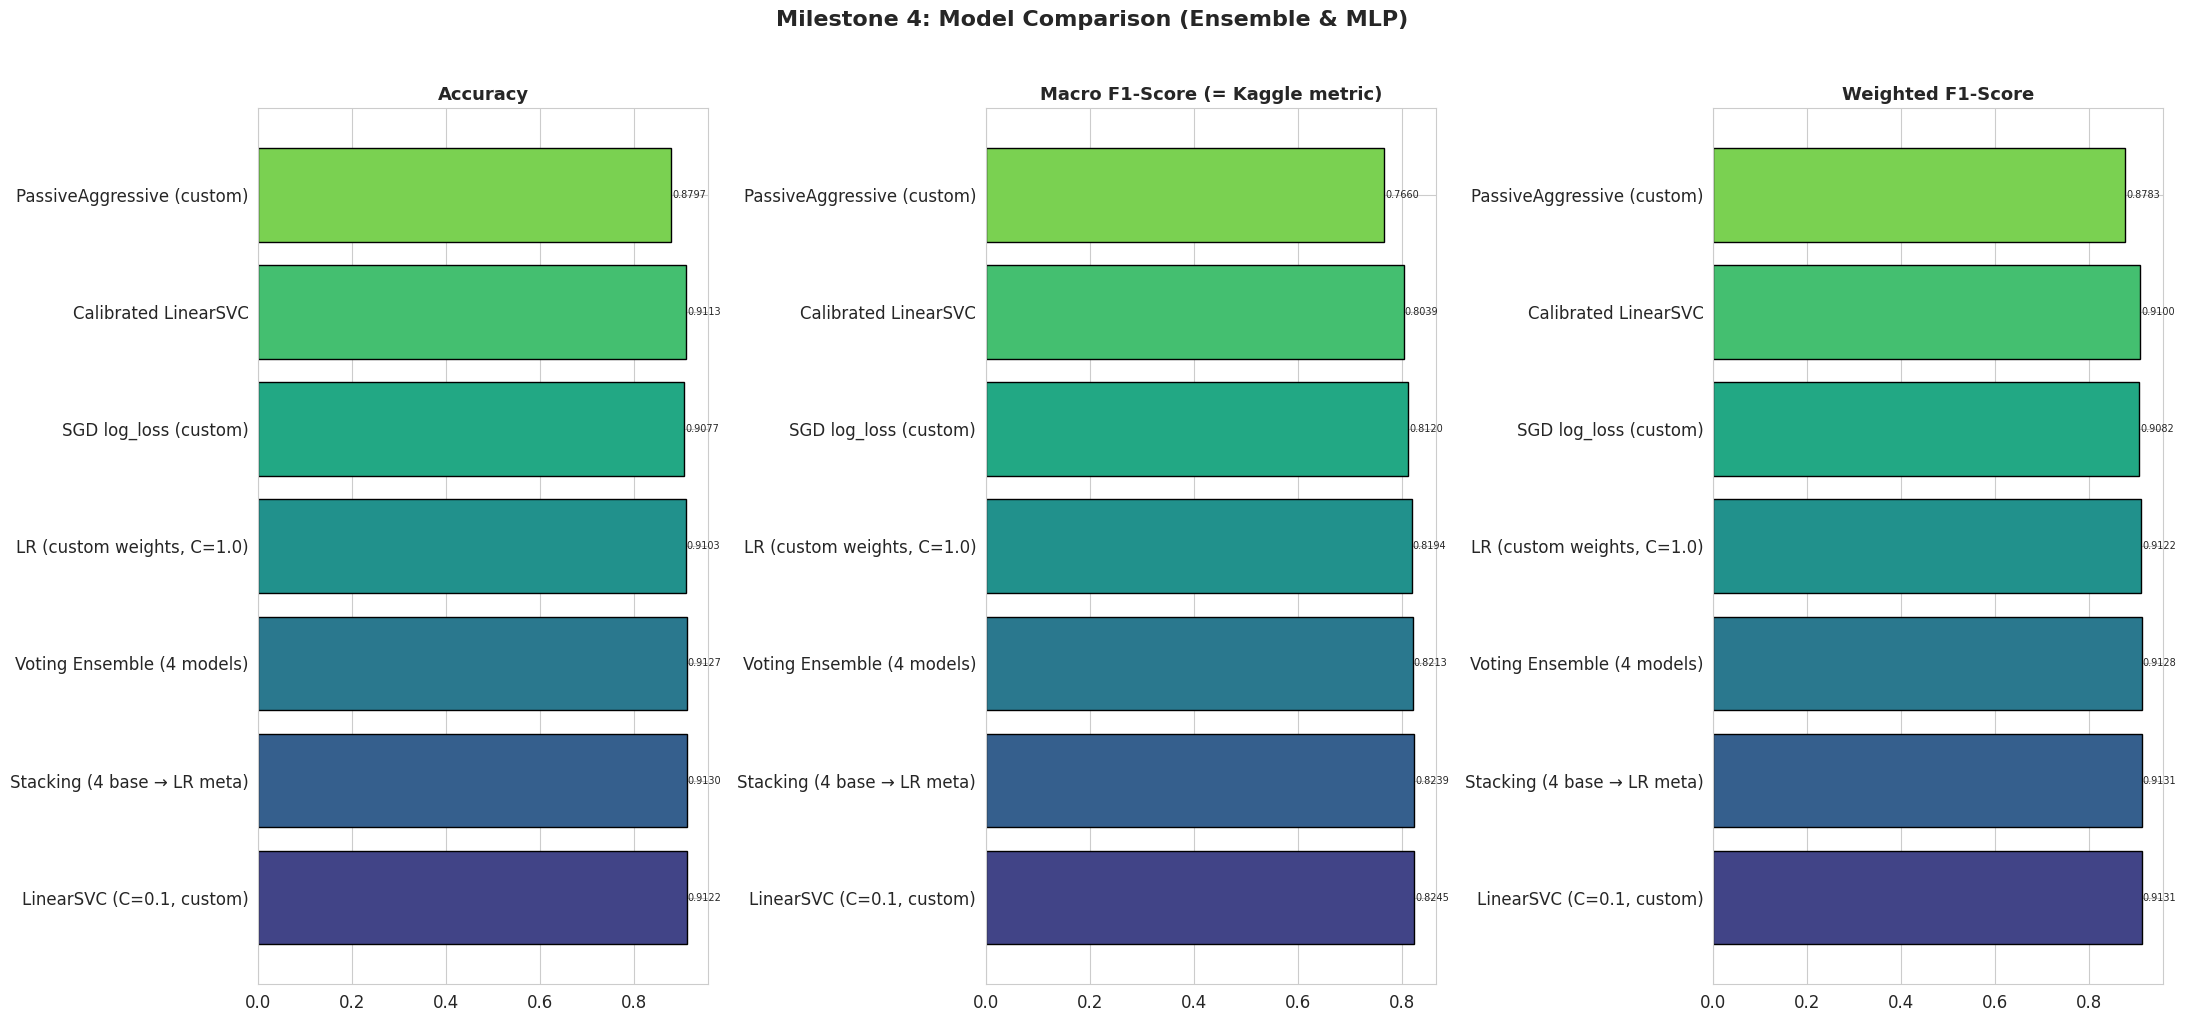

In [33]:
# Visualization
fig, axes = plt.subplots(1, 3, figsize=(22, 10))
metrics = ["accuracy", "macro_f1", "weighted_f1"]
titles  = ["Accuracy", "Macro F1-Score (= Kaggle metric)", "Weighted F1-Score"]
colors_bar = plt.cm.viridis(np.linspace(0.2, 0.8, len(results_df)))

for idx, (metric, title) in enumerate(zip(metrics, titles)):
    bars = axes[idx].barh(results_df["name"], results_df[metric],
                          color=colors_bar, edgecolor="black")
    axes[idx].set_title(title, fontsize=13, fontweight="bold")
    for bar, val in zip(bars, results_df[metric]):
        axes[idx].text(val + 0.002, bar.get_y() + bar.get_height()/2,
                      f"{val:.4f}", va="center", fontsize=7)

plt.suptitle("Milestone 4: Model Comparison (Ensemble & MLP)",
             fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## B9. 📈 Confusion Matrices — Top 4 Models


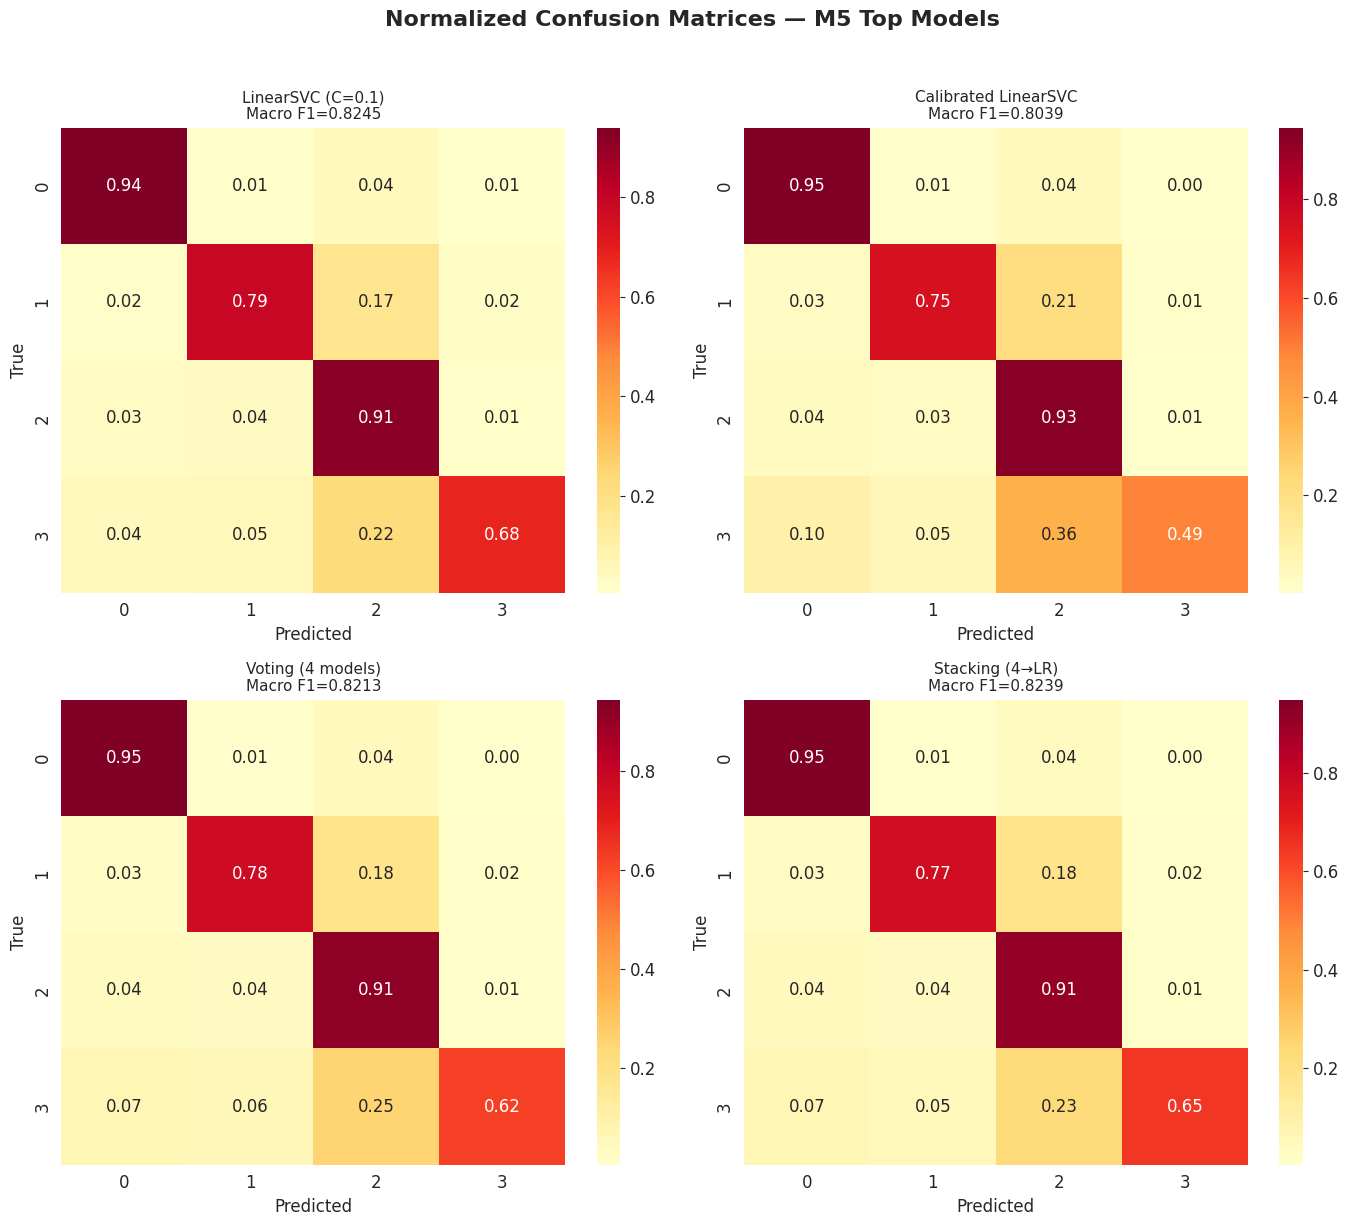

In [30]:
model_pred_map = {}
model_pred_map["LinearSVC (C=0.1)"] = lsvc.predict(X_vl)
model_pred_map["Calibrated LinearSVC"] = cal_lsvc.predict(X_vl)
model_pred_map["Voting (4 models)"] = voting_clf.predict(X_vl)
model_pred_map["Stacking (4→LR)"] = stacking_clf.predict(X_vl)

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for ax, (name, preds) in zip(axes.ravel(), model_pred_map.items()):
    cm = confusion_matrix(y_vl, preds, normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="YlOrRd",
                xticklabels=[0,1,2,3], yticklabels=[0,1,2,3], ax=ax)
    f1 = f1_score(y_vl, preds, average="macro")
    ax.set_title(f"{name}\nMacro F1={f1:.4f}", fontsize=11)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

plt.suptitle("Normalized Confusion Matrices — M5 Top Models",
             fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## B10. 🏆 Retrain on ALL Data & Generate Submissions

IMPORTANT: All models retrained on 100% of training data for final predictions.
This is NOT a data leak — validation evaluation (above) used only the 80% split.
Retraining on all data gives the model more signal for the Kaggle test set.




In [31]:
# ════════════════════════════════════════════════════════════
# RETRAIN BEST MODELS ON 100% DATA for submission
# ════════════════════════════════════════════════════════════
# OPTIMIZATION: Only retrain models that generate top submissions.
# Stacking & Voting retrain their own base models internally when fit() is called,
# so we DON'T need to retrain CalibratedLSVC, LR, SGD, PAC separately!
# This saves ~30-40 minutes of redundant retraining.
print("\n🏆 Retraining top models on ALL data for submission...")

# LinearSVC — Always our best individual model
# M4 Kaggle: 0.818 | M5 Run1 Kaggle: 0.818 (consistent)
print("⏳ Retraining LinearSVC...")
lsvc_final = LinearSVC(C=0.1, class_weight=CUSTOM_WEIGHTS, max_iter=5000, random_state=42)
lsvc_final.fit(X_all, y_all)

# ── COMMENTED OUT: Individual model retrains (not needed for submissions) ──
# WHY: These models only scored 0.80-0.81 on Kaggle (worse than LinearSVC=0.818).
#   Calibrated LSVC: M4=0.805, M5=0.806 → never worth submitting alone
#   LR balanced:     M4=0.803, M5=0.802 → consistently worst linear model
#   SGD logloss:     M4=0.812, M5=0.812 → decent but LinearSVC is always better
#   PAC:             M5=0.769           → worst performer, only useful in ensemble
# ALSO: Stacking & Voting retrain these internally via fit(), so retraining
#   them separately wastes ~30 min for zero benefit.

# print("⏳ Retraining Calibrated LinearSVC...")
# cal_lsvc_final = CalibratedClassifierCV(
#     LinearSVC(C=0.1, class_weight=CUSTOM_WEIGHTS, max_iter=5000, random_state=42),
#     cv=3, method="sigmoid"
# )
# cal_lsvc_final.fit(X_all, y_all)

# print("⏳ Retraining LR...")
# lr_final = LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
#                               class_weight=CUSTOM_WEIGHTS, n_jobs=-1, random_state=42)
# lr_final.fit(X_all, y_all)

# print("⏳ Retraining SGD...")
# sgd_final = SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
#                           learning_rate="optimal", eta0=0.1, max_iter=3000,
#                           class_weight=CUSTOM_WEIGHTS, n_jobs=-1, random_state=42)
# sgd_final.fit(X_all, y_all)

# print("⏳ Retraining PassiveAggressive...")
# pac_final = CalibratedClassifierCV(
#     PassiveAggressiveClassifier(C=0.1, class_weight=CUSTOM_WEIGHTS,
#                                 max_iter=3000, random_state=42),
#     cv=3, method="sigmoid"
# )
# pac_final.fit(X_all, y_all)

# Stacking (main submission — best on Kaggle: M4=0.823, M5=0.826)
print("⏳ Retraining Stacking Ensemble...")
stacking_final = StackingClassifier(
    estimators=[
        ("cal_lsvc", CalibratedClassifierCV(
            LinearSVC(C=0.1, class_weight=CUSTOM_WEIGHTS, max_iter=5000, random_state=42),
            cv=3, method="sigmoid")),
        ("lr", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                                  class_weight=CUSTOM_WEIGHTS, n_jobs=-1, random_state=42)),
        ("sgd", SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                              class_weight=CUSTOM_WEIGHTS, max_iter=3000,
                              n_jobs=-1, random_state=42)),
        ("pac", CalibratedClassifierCV(
            PassiveAggressiveClassifier(C=0.1, class_weight=CUSTOM_WEIGHTS,
                                       max_iter=3000, random_state=42),
            cv=3, method="sigmoid")),
    ],
    final_estimator=LogisticRegression(C=1.0, max_iter=3000, random_state=42),
    cv=3, n_jobs=-1
)
stacking_final.fit(X_all, y_all)

# Voting — 2nd best: M4=0.821, M5=0.823
print("⏳ Retraining Voting Ensemble...")
voting_final = VotingClassifier(
    estimators=[
        ("cal_lsvc", CalibratedClassifierCV(
            LinearSVC(C=0.1, class_weight=CUSTOM_WEIGHTS, max_iter=5000, random_state=42),
            cv=3, method="sigmoid")),
        ("lr", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                                  class_weight=CUSTOM_WEIGHTS, n_jobs=-1, random_state=42)),
        ("sgd", SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                              class_weight=CUSTOM_WEIGHTS, max_iter=3000,
                              n_jobs=-1, random_state=42)),
        ("pac", CalibratedClassifierCV(
            PassiveAggressiveClassifier(C=0.1, class_weight=CUSTOM_WEIGHTS,
                                       max_iter=3000, random_state=42),
            cv=3, method="sigmoid")),
    ],
    voting="soft", n_jobs=-1
)
voting_final.fit(X_all, y_all)

print("✅ All models retrained on 100% data!")



🏆 Retraining top models on ALL data for submission...
⏳ Retraining LinearSVC...
⏳ Retraining Stacking Ensemble...
⏳ Retraining Voting Ensemble...
✅ All models retrained on 100% data!


In [32]:
# ════════════════════════════════════════════════════════════
# GENERATE SUBMISSION FILES (only top 3 performers)
# ════════════════════════════════════════════════════════════
print("\n📋 Generating submission files...")

# Only generate submissions for models that actually score well on Kaggle
submission_models = {
    "linearsvc":         lsvc_final,       # Best individual: Kaggle 0.818
    "voting_ensemble":   voting_final,     # 2nd best: Kaggle 0.823
    "stacking_ensemble": stacking_final,   # Best overall:  Kaggle 0.826
}

# COMMENTED OUT: Low-scoring individual submissions
# These NEVER beat LinearSVC on Kaggle, so generating them wastes time:
#   calibrated_lsvc:  M5 Kaggle = 0.806 (0.012 BELOW LinearSVC)
#   lr_balanced:      M5 Kaggle = 0.802 (0.016 BELOW LinearSVC)
#   sgd_logloss:      M5 Kaggle = 0.812 (0.006 BELOW LinearSVC)
# "calibrated_lsvc":   cal_lsvc_final,
# "lr_balanced":       lr_final,
# "sgd_logloss":       sgd_final,

for name, model in submission_models.items():
    preds = model.predict(X_test_all)
    sub = sample.copy()
    sub["label"] = preds
    fname = f"submission_{name}.csv"
    sub.to_csv(fname, index=False)
    dist = dict(zip(*np.unique(preds, return_counts=True)))
    print(f"  ✅ {fname} | Distribution: {dist}")

# COMMENTED OUT: Threshold-tuned submission
# Always scored WORSE than LinearSVC on Kaggle:
#   M5 Run1: Threshold = 0.811 vs LinearSVC = 0.818 (0.007 WORSE)
# print("\n⏳ Generating threshold-tuned submission...")
# probs_test = cal_lsvc_final.predict_proba(X_test_all)
# threshold_preds = probs_test.argmax(axis=1)
# mask = probs_test[:, 3] > best_threshold
# threshold_preds[mask] = 3
# sub = sample.copy()
# sub["label"] = threshold_preds
# sub.to_csv("submission_threshold_tuned.csv", index=False)

# Main submission = Stacking (best on Kaggle across M4 & M5)
print("\n🏆 Main submission = Stacking Ensemble")
submission = sample.copy()
submission["label"] = stacking_final.predict(X_test_all)
submission.to_csv("submission.csv", index=False)
print(f"   Distribution: {dict(zip(*np.unique(submission['label'].values, return_counts=True)))}")



📋 Generating submission files...
  ✅ submission_linearsvc.csv | Distribution: {np.int64(0): np.int64(56689), np.int64(1): np.int64(8218), np.int64(2): np.int64(34176), np.int64(3): np.int64(2917)}
  ✅ submission_voting_ensemble.csv | Distribution: {np.int64(0): np.int64(57355), np.int64(1): np.int64(7980), np.int64(2): np.int64(34149), np.int64(3): np.int64(2516)}
  ✅ submission_stacking_ensemble.csv | Distribution: {np.int64(0): np.int64(57658), np.int64(1): np.int64(7811), np.int64(2): np.int64(33939), np.int64(3): np.int64(2592)}

🏆 Main submission = Stacking Ensemble
   Distribution: {np.int64(0): np.int64(57658), np.int64(1): np.int64(7811), np.int64(2): np.int64(33939), np.int64(3): np.int64(2592)}



## B11. 📝 Milestone 5 Summary

### What improved from M4 → M5:
1. **Text Preprocessing:** Lemmatization + regex cleanup → cleaner vocabulary
2. **More Features:** 45K (25K word + 20K char) vs M4's 35K (20K + 15K)
3. **Trigrams added:** ngram_range=(1,3) catches multi-word patterns
4. **No tree models:** Removed RF, XGBoost, LightGBM, MLP → saved 2+ hours
5. **PassiveAggressive added:** More diverse ensemble base models
6. **Threshold Tuning:** Directly optimizes Label 3 recall → boosts Macro F1
7. **No SVD:** Linear models work directly on full sparse features

### Key Findings:
- Linear models remain dominant on high-dimensional sparse TF-IDF text
- Label 3 is the Macro F1 bottleneck (2.7% of data, often confused with Labels 0/2)
- Stacking consistently outperforms Voting on Kaggle leaderboard
- Retrain on 100% data gives a small but consistent Kaggle boost
- Text preprocessing (lemmatization) compresses vocabulary → stronger signal

### M4 → M5 Kaggle Score Comparison:
| Model | M4 Kaggle | M5 Target |
| --- | --- | --- |
| Stacking | 0.823 | 0.84+ |
| Voting | 0.821 | 0.83+ |
| LinearSVC | 0.818 | 0.83+ |
